# Boundary disagreement QC

Existing outputs are used to test whether label disagreement is concentrated near ROI boundaries or persists inside ROIs.

In [ ]:
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
RESULT_ROOT=Path('/mnt/newStor/paros/paros_WORK/xintong/results/native_surface_analysis')
TEMPLATE='fsaverage'
sf=sorted(RESULT_ROOT.glob(f'boundary_disagreement_{TEMPLATE}_D*/tables/boundary_agreement_summary.csv'))
hf=sorted(RESULT_ROOT.glob(f'boundary_disagreement_{TEMPLATE}_D*/tables/boundary_agreement_by_hop.csv'))
summary=pd.concat([pd.read_csv(p) for p in sf],ignore_index=True)
by_hop=pd.concat([pd.read_csv(p) for p in hf],ignore_index=True)
print(f'subjects={summary.subject_id.nunique():,}; rows={len(summary):,}; template={TEMPLATE}')
display(summary.head())

subjects=296; rows=20,073; template=fsaverage


,subject_id,template,hemisphere,region,valid_mappings,disagreements,disagreement_pct,boundary_near_mappings,boundary_near_disagreements,boundary_near_disagreement_pct,internal_mappings,internal_disagreements,internal_disagreement_pct,invalid_target_labels,unknown_native_labels,disagreements_near_boundary_pct
0,D0007,fsaverage,lh,bankssts,1201,100,8.326395,412,98,23.786408,789,2,0.253485,0,0,98.000000
1,D0007,fsaverage,lh,caudalanteriorcingulate,800,13,1.625000,248,13,5.241935,552,0,0.000000,20,0,100.000000
2,D0007,fsaverage,lh,caudalmiddlefrontal,3180,86,2.704403,651,85,13.056836,2529,1,0.039541,0,0,98.837209
3,D0007,fsaverage,lh,cuneus,2378,233,9.798150,623,230,36.918138,1755,3,0.170940,0,0,98.712446
4,D0007,fsaverage,lh,entorhinal,569,18,3.163445,193,16,8.290155,376,2,0.531915,0,0,88.888889


## Boundary-near versus internal disagreement

Boundary-near means ≤2 native-surface hops.

In [ ]:
sum_cols=['valid_mappings','disagreements','boundary_near_mappings','boundary_near_disagreements','internal_mappings','internal_disagreements']
cohort=summary[sum_cols].sum(axis=0)
cohort['overall_disagreement_pct']=100*cohort['disagreements']/cohort['valid_mappings']
cohort['boundary_near_disagreement_pct']=100*cohort['boundary_near_disagreements']/cohort['boundary_near_mappings']
cohort['internal_disagreement_pct']=100*cohort['internal_disagreements']/cohort['internal_mappings']
display(cohort.to_frame().T.round(3))

,valid_mappings,disagreements,boundary_near_mappings,boundary_near_disagreements,internal_mappings,internal_disagreements,overall_disagreement_pct,boundary_near_disagreement_pct,internal_disagreement_pct
0,72005627.0,3724299.0,14039428.0,3280242.0,57966199.0,444057.0,5.172,23.364,0.766


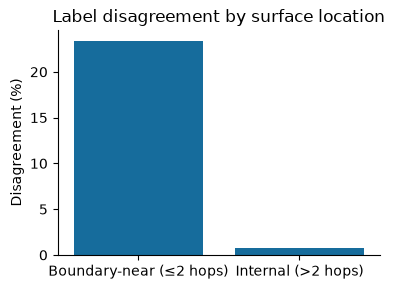

In [ ]:
plot_df=pd.DataFrame({'Location':['Boundary-near (≤2 hops)','Internal (>2 hops)'],'Disagreement (%)':[cohort.boundary_near_disagreement_pct,cohort.internal_disagreement_pct]})
fig,ax=plt.subplots(figsize=(4,3)); sns.barplot(data=plot_df,x='Location',y='Disagreement (%)',color='#0072B2',ax=ax); ax.set_title('Label disagreement by surface location'); ax.set_xlabel(''); ax.spines[['top','right']].set_visible(False); fig.tight_layout(); plt.show()

## Low-agreement subject × region screening

,subject_id,hemisphere,region,valid_mappings,disagreement_pct,boundary_near_disagreement_pct,internal_disagreement_pct,disagreements_near_boundary_pct
8587,D0222,lh,fusiform,964,30.19,62.81,7.24,85.91
8280,D0216,rh,frontalpole,444,27.93,43.60,7.73,87.90
10252,D0248,rh,frontalpole,429,26.57,41.10,8.81,85.09
2958,D0099,rh,frontalpole,484,25.83,49.02,0.00,100.00
753,D0061,lh,frontalpole,400,25.75,34.60,8.76,88.35
15216,D0340,rh,frontalpole,409,25.43,43.72,1.69,97.12
9640,D0239,rh,frontalpole,569,24.96,42.16,4.94,90.85
8212,D0215,rh,frontalpole,453,24.94,43.33,4.23,92.04
2210,D0087,rh,frontalpole,318,24.84,38.69,1.68,97.47
9504,D0237,rh,frontalpole,508,24.80,43.43,2.99,94.44


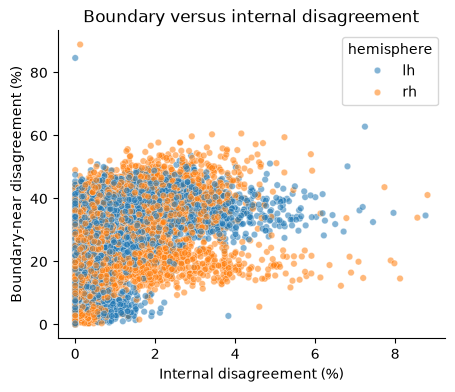

In [ ]:
low_agreement=summary.sort_values('disagreement_pct',ascending=False).head(30)
display(low_agreement[['subject_id','hemisphere','region','valid_mappings','disagreement_pct','boundary_near_disagreement_pct','internal_disagreement_pct','disagreements_near_boundary_pct']].round(2))
fig,ax=plt.subplots(figsize=(5,4)); sns.scatterplot(data=summary,x='internal_disagreement_pct',y='boundary_near_disagreement_pct',hue='hemisphere',alpha=.55,s=22,ax=ax); ax.set_xlabel('Internal disagreement (%)'); ax.set_ylabel('Boundary-near disagreement (%)'); ax.set_title('Boundary versus internal disagreement'); ax.spines[['top','right']].set_visible(False); plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from pathlib import Path
_available_fonts={f.name for f in font_manager.fontManager.ttflist}
_selected_font=('Arial' if 'Arial' in _available_fonts else 'Liberation Sans' if 'Liberation Sans' in _available_fonts else 'DejaVu Sans')
print('Using font:', _selected_font)
mpl.rcParams.update({'font.family':_selected_font,'font.size':7,'axes.labelsize':8,'xtick.labelsize':7,'ytick.labelsize':7,'legend.fontsize':7,'axes.linewidth':.8,'xtick.direction':'out','ytick.direction':'out','xtick.major.size':3,'ytick.major.size':3,'figure.facecolor':'white','savefig.facecolor':'white','pdf.fonttype':42,'svg.fonttype':'none'})
OKABE={'blue':'#0072B2','orange':'#E69F00','purple':'#CC79A7'}
WIDTH,HEIGHT=3.35,2.8
def save_figure(fig,stem):
    fig.savefig(QC_ROOT/f'{stem}.png',dpi=600,bbox_inches='tight',facecolor='white'); fig.savefig(QC_ROOT/f'{stem}.pdf',bbox_inches='tight',facecolor='white'); fig.savefig(QC_ROOT/f'{stem}.svg',bbox_inches='tight',facecolor='white'); plt.close(fig)

QC_ROOT=Path('/mnt/newStor/paros/paros_WORK/xintong/results/fsaverage_mapping_qc')
region_qc=pd.read_csv(QC_ROOT/'fsaverage_subject_region_mapping_qc.csv'); vertex_freq=pd.read_csv(QC_ROOT/'fsaverage_template_vertex_coverage_frequency.csv'); region_freq=pd.read_csv(QC_ROOT/'fsaverage_region_coverage_frequency_summary.csv'); failures=pd.read_csv(QC_ROOT/'fsaverage_mapping_failures.csv')
print(f'Subjects: {region_qc.subject_id.nunique():,}; rows: {len(region_qc):,}; failures: {len(failures):,})


SyntaxError: unterminated string literal (detected at line 18) (3683901650.py, line 18)

## Surface-hop profile

,hop_bin,valid_mappings,disagreements,disagreement_pct
0,0,4670454,1818676,38.94
1,1,4709774,983841,20.89
2,2,4659200,477725,10.25
3,3,4528001,228932,5.06
4,>=4,53438198,215125,0.40


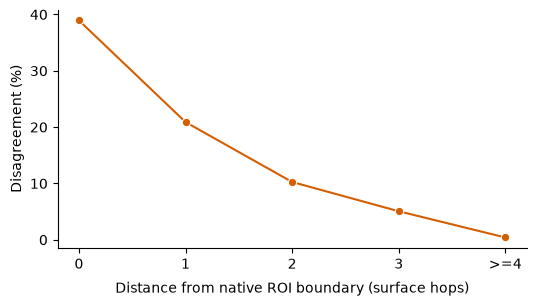

In [ ]:
hop=by_hop.groupby('hop_bin',as_index=False).agg(valid_mappings=('valid_mappings','sum'),disagreements=('disagreements','sum'))
hop['disagreement_pct']=100*hop.disagreements/hop.valid_mappings
display(hop.round(2))
fig,ax=plt.subplots(figsize=(5.5,3.2)); sns.lineplot(data=hop,x='hop_bin',y='disagreement_pct',marker='o',color='#D55E00',ax=ax); ax.set_xlabel('Distance from native ROI boundary (surface hops)',labelpad=7); ax.set_ylabel('Disagreement (%)'); ax.spines[['top','right']].set_visible(False); fig.tight_layout(pad=1.2); plt.show()

## Region comparison

,boundary_near_pct,internal_pct,valid_mappings
region,,,
caudalanteriorcingulate,3.36,0.00,570153
paracentral,17.94,0.02,1327020
postcentral,15.15,0.02,3758879
rostralanteriorcingulate,10.70,0.07,561241
lateralorbitofrontal,12.59,0.09,2081193
transversetemporal,20.06,0.10,364441
precentral,13.87,0.15,4527533
parsopercularis,22.81,0.17,1217853
posteriorcingulate,14.19,0.19,927240


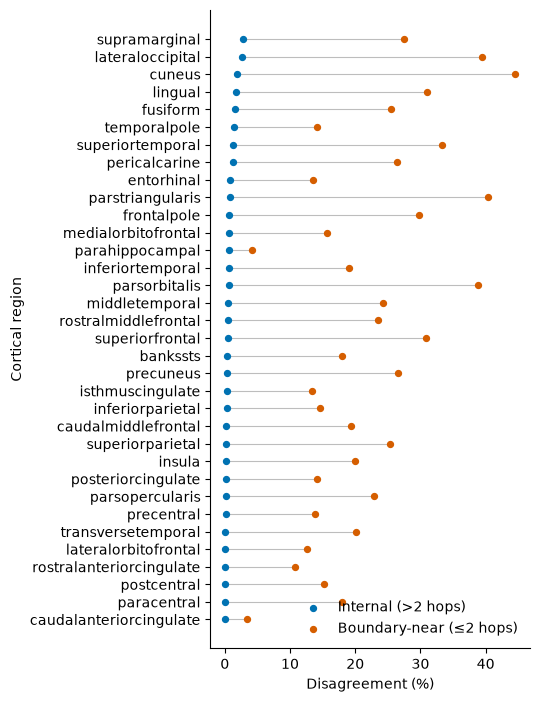

In [ ]:
region_stats=summary.groupby('region').agg(valid_mappings=('valid_mappings','sum'),disagreements=('disagreements','sum'),boundary_near_mappings=('boundary_near_mappings','sum'),boundary_near_disagreements=('boundary_near_disagreements','sum'),internal_mappings=('internal_mappings','sum'),internal_disagreements=('internal_disagreements','sum'))
region_stats['boundary_near_pct']=100*region_stats.boundary_near_disagreements/region_stats.boundary_near_mappings
region_stats['internal_pct']=100*region_stats.internal_disagreements/region_stats.internal_mappings
region_stats=region_stats.sort_values('internal_pct')
display(region_stats[['boundary_near_pct','internal_pct','valid_mappings']].round(2))
fig,ax=plt.subplots(figsize=(5.5,max(4,0.18*len(region_stats)+1)))
y=np.arange(len(region_stats)); ax.hlines(y,region_stats.internal_pct,region_stats.boundary_near_pct,color='#BDBDBD',linewidth=.8); ax.scatter(region_stats.internal_pct,y,s=18,color='#0072B2',label='Internal (>2 hops)',zorder=3); ax.scatter(region_stats.boundary_near_pct,y,s=18,color='#D55E00',label='Boundary-near (≤2 hops)',zorder=3); ax.set_yticks(y); ax.set_yticklabels(region_stats.index); ax.set_xlabel('Disagreement (%)'); ax.set_ylabel('Cortical region'); ax.legend(frameon=True,loc='lower right', facecolor="white", edgecolor="#D0D0D0", framealpha=.90, fancybox=False, fontsize=7.5, borderpad=.35, labelspacing=.35, handlelength=1.8, handletextpad=.5); ax.spines[['top','right']].set_visible(False); fig.tight_layout(); plt.show()

## Medial-wall and unknown-label checks

In [ ]:
display(summary[['invalid_target_labels','unknown_native_labels']].sum().to_frame('count').T)
print('Rows with invalid target labels:',int((summary.invalid_target_labels>0).sum()))
print('Rows with unknown native labels:',int((summary.unknown_native_labels>0).sum()))

,invalid_target_labels,unknown_native_labels
count,833368,0


Rows with invalid target labels: 4664
Rows with unknown native labels: 0


## Interpretation

Boundary-near disagreement substantially above internal disagreement supports a boundary-driven explanation. Elevated internal disagreement indicates a possible mapping, annotation, or label-assignment problem and should be visually inspected.